# Using Classification to Predict E.coli Contamination in River Water

**Goal**: The goal of this project is to determine whether machine learning classification models can use routine water quality measurements to predict *E. coli* exceedances in river water, defined as concentrations of ≥100 per 100 mL. Several models, including Logistic Regression, Support Vector Classification, Decision Trees, Random Forest, Gradient Boosting, and K-Nearest Neighbors, were trained and evaluated using cross-validation. The best-performing model was then analyzed to identify the water quality measurements most influential in predicting *E. coli* exceedances.

**Data Problem**:  The task is to train and optimize binary classification models to predict whether a river water sample meets or exceeds the *E. coli* threshold of 100 per 100 mL (positive) or falls below this threshold (negative).

**Expected Results**: The expected result of this project is a model that uses less expensive and less labor-intensive water quality measurements to predict whether a sample is positive or negative for *E. coli*. Since *E. coli* is a biological contaminant, recall will be the priotized performance metric because it is imperative that the model correctly identifies true positivies and minimizes false negatives.

**Data**: The data were sourced from The Global Freshwater Quality Database GEMState, maintained by the United Nations Environment Programme (UNEP).

* Link: https://portal.gemstat.org/applications/public.html?publicuser=PublicUser#gemstat/Stations

* **Geographic Scope**: Data were collected from sampling across the following Mexican states/regions: Armeria, Balsas, Candelaria, Coatan Achute, Colorado, Concepcion, Fuerte Nuevo, Grijalva, Hondo, Panuco, Papaloadan, Rio Grande, San Pedro, Santa Clara, Suchiate, Tijuana, Verde, Yaqui.

#### Import and Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

pd.set_option('display.max_columns', 50)

import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

#### Upload data 
* Data was downloaded from GEMStat Database in five batches due to download size constraints imposed by GEMStat.

In [2]:
files = [
    'samples_1.csv',
    'samples_2.csv',
    'samples_3.csv',
    'samples_4.csv',
    'samples_5.csv'
]

dataframes = []

for file in files:
    df = pd.read_csv(file, sep=';', low_memory=False)
    dataframes.append(df)

#### Data Concatenation
* The five dataframes were concatenated into a single dataframe with a shape of (1,222,396, 11).

In [3]:
# Check the shape of each dataframe and calculate total rows
rows = 0

for df in dataframes:
    print(df.shape)
    rows += df.shape[0]

print("Total rows:", rows)

(338992, 11)
(82659, 11)
(295389, 11)
(249884, 11)
(255472, 11)
Total rows: 1222396


In [4]:
# Concatenate dataframes vertically and reset the index.
df = pd.concat(dataframes, axis=0).reset_index(drop=True)

In [5]:
# Confirm correct concatenation.
df.shape

(1222396, 11)

#### Initial Data Cleaning
* Rows rated **Poor** or **Suspect** in the `Data Quality` column were removed based on GEMStat's plausibility ratings.
* Turbidity was the only parameter recorded in multiple units: 50,783 samples in NTU and 137 in JCU. The JCU samples (0.27% of turbidity measurements) were removed to maintain unit consistency.
* The resulting dataframe had a shape of (1,135,919, 11).

In [6]:
# Drop rows with Poor or Suspect Data Quality
df.drop(df[df['Data Quality'].isin(['Suspect', 'Poor'])].index, inplace=True)

In [7]:
# Make sure units are consistent
df.groupby('Parameter Code')['Unit'].unique()

Parameter Code
BOD              [mg/l]
COD              [mg/l]
EC              [µS/cm]
ECOLI        [1/100 ml]
FECALCOLI    [1/100 ml]
NH3N             [mg/l]
NO2N             [mg/l]
NO3N             [mg/l]
O2-Dis           [mg/l]
TDS              [mg/l]
TEMP               [°C]
TKN              [mg/l]
TN               [mg/l]
TOC              [mg/l]
TON              [mg/l]
TP               [mg/l]
TRP              [mg/l]
TSS              [mg/l]
TURB         [JCU, NTU]
pH                [---]
Name: Unit, dtype: object

In [8]:
# Turbidity uses two units. Investigate!
df[df['Parameter Code'] == 'TURB']['Unit'].value_counts()

Unit
NTU    50783
JCU      137
Name: count, dtype: int64

In [9]:
# Drop JCU turbidity measurements to maintain unit consistency.
df.drop(df[(df['Parameter Code'] == 'TURB') & (df['Unit'] == 'JCU')].index, inplace=True)

In [10]:
# Check
df[df['Parameter Code'] == 'TURB']['Unit'].value_counts()

Unit
NTU    50783
Name: count, dtype: int64

In [11]:
df.shape

(1135919, 11)

#### Pivot DataFrame
* Reshaped the dataset so each row represents a unique sampling event(station, date, time, and depth), with each water-quality parameter stored in its own column.
* Calculated the mean value when multiple measurements existed for the same parameter and sampling event.
* Reset the index and removed the columns axis name for cleaner output.
* Rows without an ECOLI measurement were dropped.
* Resulting dataframe has the shape (46467,24).

In [12]:
# Pivot the dataframe so each row represents a sampling event.
df_pivot = df.pivot_table(
    index=['GEMS Station Number', 'Sample Date', 'Sample Time', 'Depth'],
    columns='Parameter Code',
    values='Value',
    aggfunc='mean'
).reset_index()

df_pivot.columns.name = None

In [13]:
df_pivot.head(1)

,GEMS Station Number,Sample Date,Sample Time,Depth,BOD,COD,EC,ECOLI,FECALCOLI,NH3N,NO2N,NO3N,O2-Dis,TDS,TEMP,TKN,TN,TOC,TON,TP,TRP,TSS,TURB,pH
0,GTM00080,2004-01-15,12:00,1.0,NaN,NaN,152.0,NaN,NaN,NaN,0.078,2.7,6.5,111.0,23.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.81,7.7


In [14]:
# Rows without an ECOLI measurement were dropped.
df_pivot = df_pivot.dropna(
    subset=['ECOLI']
).reset_index(drop=True)

#### EDA
* The dataset consists of 22 numeric columns (21 after the index column is dropped) and 3 string columns (station number, sample date, sample time), with 46,467 sampling events.
* Missing values are present in every water-quality column except Depth and ECOLI. They range from 239 (FECALCOLI) to 6,491 (TKN), or 0.51% to 13.97% of rows, so no column is missing enough data to drop.
* For most parameters, the mean is much larger than the median (for example, ECOLI has a mean of about 23,710 vs. a median of 256, and NH3N has a mean of 2.89 vs. a median of 0.14). This indicates right-skewed distributions driven by a smaller number of extreme values.
* Histograms of BOD, COD, TN, and TP show a long right tail, so scaling that is robust to outliers is appropriate.
* Depth is nearly constant: the 25th, 50th, and 75th percentiles are all 0.3 m, although values range from 0.15 to 7.52 m.
* ECOLI and FECALCOLI show a strong positive relationship, which is expected since E. coli is a subset of fecal coliforms. This motivates comparing models with and without FECALCOLI.
* ECOLI is highly concentrated at the upper end: the 90th and 95th percentiles are both 24,000, and the maximum is 24,196,000. The ten largest values are all identical (24,196,000) and look like a reporting limit rather than true measurements, so they were kept.

In [15]:
df_pivot.info()

<class 'pandas.DataFrame'>
RangeIndex: 46467 entries, 0 to 46466
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   GEMS Station Number  46467 non-null  str    
 1   Sample Date          46467 non-null  str    
 2   Sample Time          46467 non-null  str    
 3   Depth                46467 non-null  float64
 4   BOD                  45890 non-null  float64
 5   COD                  45348 non-null  float64
 6   EC                   46043 non-null  float64
 7   ECOLI                46467 non-null  float64
 8   FECALCOLI            46228 non-null  float64
 9   NH3N                 45751 non-null  float64
 10  NO2N                 46003 non-null  float64
 11  NO3N                 45897 non-null  float64
 12  O2-Dis               44477 non-null  float64
 13  TDS                  46051 non-null  float64
 14  TEMP                 46096 non-null  float64
 15  TKN                  39976 non-null  float64
 1

In [16]:
df_pivot.describe()

,Depth,BOD,COD,EC,ECOLI,FECALCOLI,NH3N,NO2N,NO3N,O2-Dis,TDS,TEMP,TKN,TN,TOC,TON,TP,TRP,TSS,TURB,pH
count,46467.000000,45890.000000,45348.000000,46043.000000,4.646700e+04,4.622800e+04,45751.000000,46003.000000,45897.000000,44477.000000,46051.000000,46096.000000,39976.000000,45181.000000,45565.000000,45808.000000,45862.000000,45615.000000,46085.000000,46044.000000,45483.000000
mean,0.327752,19.294810,65.225876,1057.312154,2.371018e+04,2.891217e+04,2.892247,0.110347,1.054105,5.847273,705.321386,24.658473,1.412210,6.102840,11.672979,2.283891,1.107084,0.739656,113.735757,76.555971,7.826583
std,0.086054,57.689633,116.839579,2174.548152,5.426786e+05,5.892971e+05,9.103807,0.485554,3.136869,2.479978,1553.483549,4.776764,2.626740,12.229492,37.544427,6.340456,2.976128,2.633456,576.867710,432.740965,0.523392
min,0.150000,1.000000,0.970000,3.820000,1.000000e+00,1.000000e+00,0.003000,0.000500,0.000430,0.050000,2.444800,4.000000,0.003000,0.006700,0.060000,0.000000,0.001000,0.000500,0.100000,0.019000,3.800000
25%,0.300000,2.000000,11.900000,302.000000,3.000000e+01,1.500000e+02,0.056000,0.005000,0.081000,4.300000,193.280000,21.200000,0.328000,0.720400,1.920000,0.206000,0.052144,0.012000,10.000000,2.500000,7.500000
50%,0.300000,3.300000,26.620000,592.000000,2.560000e+02,1.789000e+03,0.140000,0.008470,0.313300,6.030000,378.880000,25.200000,0.624441,1.401000,3.890000,0.514505,0.144773,0.058000,20.000000,8.400000,7.800000
75%,0.300000,10.200000,57.012500,1196.850000,4.600000e+03,2.400000e+04,0.720000,0.037900,0.844000,7.400000,766.080000,28.300000,1.329254,4.711003,8.320000,1.282745,0.793975,0.362050,59.000000,32.600000,8.200000
max,7.520000,985.000000,1000.000000,99770.000000,2.419600e+07,2.419600e+07,414.400000,20.316800,111.546160,86.000000,43128.000000,48.200000,77.901500,99.811000,2407.000000,98.828000,67.380000,92.950000,39780.000000,19900.000000,10.500000


##### EDA: 1. Investigate extreme values for ECOLI, FECALCOLI, TURB and TDS
* `ECOLI` and `FECALCOLI` had repeated measurements reaching 24,196,000. These values were flagged and `Fair` data quality, suggesting measurements exceeding a reporting limit rather than an error.
* Unlike ECOLI and FECALCOLI, TURB and TDS show several high but varying measurements rather than the same repeated maximum. These patterns may reflect genuine extreme water quality events. Upon further investigation, the top 3 maximum values were flagged as well.

In [17]:
# Inspect the highest measurements for each feature.
for col in ['ECOLI', 'FECALCOLI', 'TURB', 'TDS']:
    print(f'\nHighest {col} measurements:')
    display(
        df_pivot.nlargest(10, col)[
            ['GEMS Station Number', 'Sample Date', 'Sample Time', 'Depth', col]
        ]
    )


Highest ECOLI measurements:


,GEMS Station Number,Sample Date,Sample Time,Depth,ECOLI
674,MEX00213,2018-07-09,12:00,0.3,24196000.0
945,MEX00263,2019-01-23,12:00,0.3,24196000.0
980,MEX00264,2018-02-09,12:00,0.3,24196000.0
1117,MEX00272,2019-01-23,12:00,0.3,24196000.0
12600,MEX01318,2018-04-12,12:00,0.3,24196000.0
22498,MEX02192,2018-07-27,12:00,0.3,24196000.0
22499,MEX02192,2018-10-22,12:00,0.3,24196000.0
22500,MEX02192,2018-12-05,12:00,0.3,24196000.0
22501,MEX02192,2019-03-01,12:00,0.3,24196000.0
22502,MEX02192,2019-08-28,12:00,0.3,24196000.0



Highest FECALCOLI measurements:


,GEMS Station Number,Sample Date,Sample Time,Depth,FECALCOLI
674,MEX00213,2018-07-09,12:00,0.3,24196000.0
945,MEX00263,2019-01-23,12:00,0.3,24196000.0
980,MEX00264,2018-02-09,12:00,0.3,24196000.0
986,MEX00264,2019-01-23,12:00,0.3,24196000.0
1114,MEX00272,2018-07-16,12:00,0.3,24196000.0
1117,MEX00272,2019-01-23,12:00,0.3,24196000.0
12600,MEX01318,2018-04-12,12:00,0.3,24196000.0
22498,MEX02192,2018-07-27,12:00,0.3,24196000.0
22499,MEX02192,2018-10-22,12:00,0.3,24196000.0
22500,MEX02192,2018-12-05,12:00,0.3,24196000.0



Highest TURB measurements:


,GEMS Station Number,Sample Date,Sample Time,Depth,TURB
41230,MEX03892,2017-03-13,12:00,0.3,19900.0
41310,MEX03894,2017-03-13,12:00,0.3,19500.0
15500,MEX01662,2015-09-16,12:00,0.3,16780.0
6378,MEX00999,2017-08-01,12:00,0.3,16700.0
40325,MEX03819,2015-08-21,12:00,0.3,15460.0
6360,MEX00999,2014-09-02,12:00,0.3,11100.0
6683,MEX01007,2014-07-07,12:00,0.3,10720.0
42224,MEX03934,2014-07-21,12:00,0.3,10600.0
6806,MEX01010,2014-08-26,12:00,0.3,10000.0
15268,MEX01653,2013-09-21,12:00,0.3,10000.0



Highest TDS measurements:


,GEMS Station Number,Sample Date,Sample Time,Depth,TDS
13598,MEX01525,2013-04-27,12:00,0.3,43128.0
45857,MEX05083,2016-05-05,12:00,0.5,42491.2
37836,MEX03525,2018-11-06,12:00,0.3,42080.0
33240,MEX02735,2013-01-07,12:00,0.3,40872.8
13543,MEX01522,2013-04-27,12:00,0.3,40829.6
37812,MEX03525,2014-09-18,12:00,0.3,40408.0
13566,MEX01523,2013-04-27,12:00,0.3,40378.4
12360,MEX01262,2014-09-24,12:00,0.3,40256.0
12368,MEX01263,2014-09-26,12:00,0.3,40232.0
7841,MEX01038,2014-09-26,12:00,0.3,40144.0


##### 2. EDA: Analyze Missing Data
* Most features had less than 3% missing data, making them relatively complete for prediction.
* TKN had the highest missingness at approximately 14%, potentially reducing its reliability as a predictor.
* O2-Dis had 4.28% missing data, while all remaining measurements had less than 3% missingness.
* ECOLI, the target variable, had no missing values.

In [18]:
# Calculate the percentage of missing values for each feature.
missing_pct = (df_pivot.isnull().mean() * 100).sort_values(ascending=False)

display(missing_pct.to_frame(name='Missing Percentage'))

,Missing Percentage
TKN,13.969053
O2-Dis,4.282609
TN,2.767555
COD,2.408161
pH,2.117632
TOC,1.941163
TRP,1.833559
NH3N,1.540878
TON,1.418211
TP,1.301999


##### 3. EDA: Target Analysis
- E. coli concentrations were log-transformed using `np.log1p()` to visualize the distribution and spread of measurements.
- Most measurements fell between transformed values of 1 and 10, corresponding to approximately 1.7 to 22,025 E. coli units per 100 mL.
- A few observations occurred around 12–14, with very few near 17, indicating a long right tail of extreme concentrations.

<Axes: title={'center': 'Distribution of E. coli Measurements (Log-Transformed)'}, xlabel='Log(E. coli + 1)', ylabel='Frequency'>

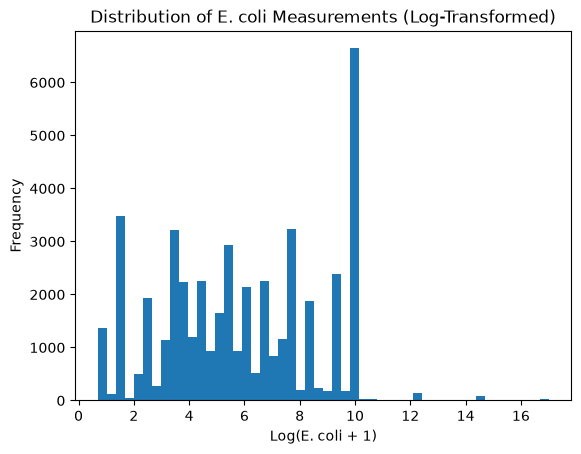

In [19]:
# Plot the distribution of E. coli measurements using a log scale.
np.log1p(df_pivot['ECOLI']).plot(
    kind='hist', bins=50,
    title='Distribution of E. coli Measurements (Log-Transformed)',
    xlabel='Log(E. coli + 1)', ylabel='Frequency'
)

In [20]:
# Convert log-transformed values back to original E. coli concentrations.
for i in range(0, 17, 1):
    print(i, np.expm1(i))

0 0.0
1 1.7182818284590453
2 6.38905609893065
3 19.085536923187668
4 53.598150033144236
5 147.4131591025766
6 402.4287934927351
7 1095.6331584284585
8 2979.9579870417283
9 8102.083927575384
10 22025.465794806718
11 59873.14171519782
12 162753.79141900392
13 442412.3920089205
14 1202603.2841647768
15 3269016.3724721107
16 8886109.520507872


##### 4. EDA: Investigating Correlations
* EC and TDS had a perfect positive correlation of 1.00, suggesting they may contain redundant information or represent equivalent measurements in this dataset.
* ECOLI and FECALCOLI had a very strong positive correlation of 0.98, indicating that these two microbiological measurements tend to increase together.
* BOD and COD had a strong positive correlation of 0.82, meaning samples with higher biological oxygen demand tended to have higher chemical oxygen demand.
* TSS and TURB had a strong positive correlation of 0.83, indicating that suspended solids tended to increase alongside turbidity.
* NH3N and TN had a strong positive correlation of 0.86, while NH3N and TKN had a correlation of 0.83, indicating strong relationships among nitrogen measurements.
* TN and TKN had a strong positive correlation of 0.71, and TN and TON had a correlation of 0.75.
* BOD and TOC had a strong positive correlation of 0.78, suggesting that higher biological oxygen demand was associated with higher total organic carbon.
* O2-Dis and BOD had a moderate negative correlation of −0.35, while O2-Dis and COD had a correlation of −0.37. Higher oxygen demand was associated with lower dissolved oxygen.
* Depth had generally weak correlations with most measurements, although it had a positive correlation of 0.17 with pH.
* Temperature had generally weak correlations with the other measurements, suggesting limited linear relationships in this dataset.

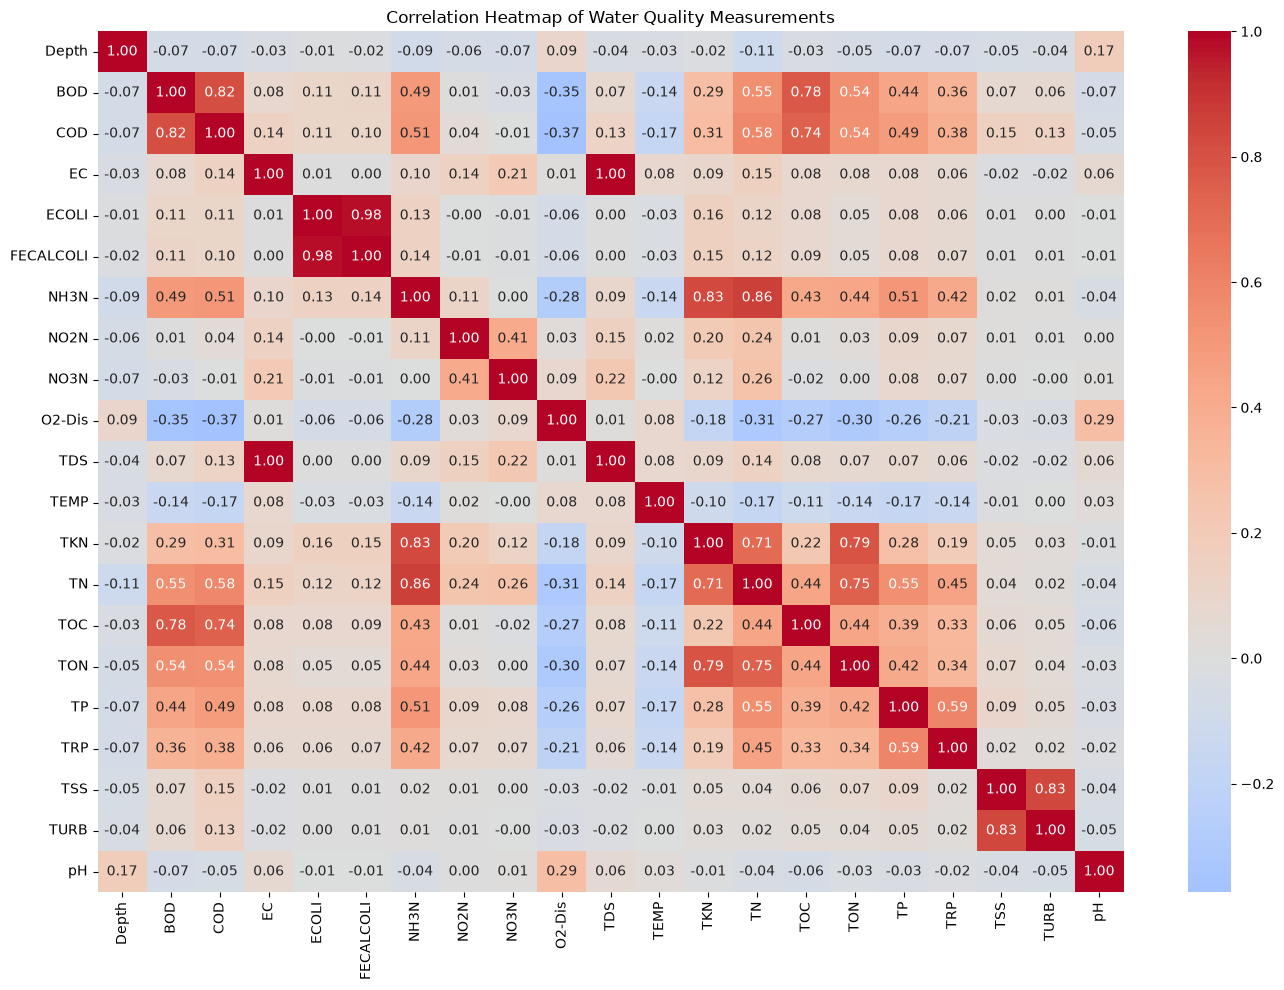

In [21]:
# Plot the correlation heatmap for water-quality measurements.
plt.figure(figsize=(14, 10))
sns.heatmap(
    df_pivot
    .select_dtypes(include='number')
    .corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)
plt.title('Correlation Heatmap of Water Quality Measurements')
plt.tight_layout()
plt.show()

#### Data Cleaning
* There are 0 duplicated rows.
* Missing values were handled using SimpleImputer() during preprocessing.
* 707 rows missing more than 25% of features were dropped.
* `Gems Station Number`, `Sample Date`, `Sample Time`, `FECALCOLI`, and `EC` were dropped from the dataset. `FECALCOLI` because it is highly correlated to `ECOLI` and `EC` because it is highly correlated to `TDS` and has more missing values.
* According to the World Health Organization, E.coli measures of 100MPN/100mL or more is considered high or very high risk. Therefore, I established 100 as my baseline and samples less than 100 were labeled 0 and samples greater than equal to 100 were labeled 1.
* The class distibution of the target variable E.Coli was 0.620 positive and 0.380 negative.

In [22]:
df_pivot.shape

(46467, 24)

In [23]:
# Check for duplicates
df_pivot.duplicated().sum()

np.int64(0)

In [24]:
df_pivot.columns

Index(['GEMS Station Number', 'Sample Date', 'Sample Time', 'Depth', 'BOD',
       'COD', 'EC', 'ECOLI', 'FECALCOLI', 'NH3N', 'NO2N', 'NO3N', 'O2-Dis',
       'TDS', 'TEMP', 'TKN', 'TN', 'TOC', 'TON', 'TP', 'TRP', 'TSS', 'TURB',
       'pH'],
      dtype='str')

In [25]:
# Drop rows missing more than 25% of features that have missing values.
exclude = ['Sample Time', 'Depth', 'Sample Date', 'ECOLI', 'GEMS Station Number']
feature_cols = df_pivot.columns.difference(exclude)

# Keep rows with at most 25% of the feature columns missing
df_pivot = df_pivot[df_pivot[feature_cols].isnull().mean(axis=1) <= 0.25]

In [26]:
df_pivot.shape

(45760, 24)

In [27]:
# Drop gems station number, sample date, sample time, fecalcoli, and ec
df_pivot = df_pivot.drop(columns=['GEMS Station Number', 'Sample Date', 'Sample Time', 'FECALCOLI', 'EC'])

In [28]:
# Check data types
df_pivot.dtypes

Depth     float64
BOD       float64
COD       float64
ECOLI     float64
NH3N      float64
NO2N      float64
NO3N      float64
O2-Dis    float64
TDS       float64
TEMP      float64
TKN       float64
TN        float64
TOC       float64
TON       float64
TP        float64
TRP       float64
TSS       float64
TURB      float64
pH        float64
dtype: object

In [29]:
# Turn e.coli into classes. 0 = negative or 1 = positive
df_pivot["ECOLI"] = np.where(df_pivot["ECOLI"] < 100, 0, 1)

In [30]:
# Check if ECOLI is now correctly in classes
df_pivot["ECOLI"].unique()

array([1, 0])

In [31]:
# Class distribution of E. coli target
print(df_pivot['ECOLI'].value_counts(normalize=True).round(3))

ECOLI
1    0.62
0    0.38
Name: proportion, dtype: float64


#### 6. Model Building

**Primary metric: recall.** Recall = true positives / (true positives + false negatives). It answers, of all the samples that really were high risk, what share did the model catch? Recall was chosen because a false negative poses a serious public health safety risk by leaving people exposed to unsafe water with no warning. Since missing contamination is the more serious error, the model is judged mainly on how much contamination it catches.

**Supporting metrics:** Recall can be inflated by flagging everything, so it is read alongside:
* **Precision**: Precision asks, of the samples flagged high risk, how many truly were. This keeps false alarms in check.
* **ROC-AUC**: ROC-AUC answers how well the model ranks high-risk samples above lower-risk ones across all thresholds, independent of the 0.5 cutoff.
* **Accuracy and F1** These two scores are reported for completeness. Accuracy is compared against the baseline below.

##### Baseline
The baseline model is 62.03% and is the percent of positive samples among total samples. It gives me a benchmark for model performance. 

##### Preprocessing
* **Features:** All water-quality measurements except FECALCOLI (a near-duplicate of the E. coli signal) and EC (derived from TDS).
* **Split:** 75% training / 25% testing, stratified on the target so both sets keep the same class balance.
* **Imputation:** Missing values are filled with the median inside the pipeline, fit on training data only, so no information leaks from the test set. The median is used because the distributions are heavily right-skewed.
* **Scaling:** `RobustScaler` centers on the median and scales by the IQR, which limits the influence of the extreme values found in EDA.

##### Models Compared
Six classifiers were trained in identical pipelines: Logistic Regression (`max_iter=1000` to ensure convergence), Decision Tree, Random Forest, Gradient Boosting, Support Vector Classifier, and K-Nearest Neighbors. A fixed `random_state=42` is used for every model with built-in randomness so results are reproducible.

##### Cross-Validation and Tuning
* **Grid search:** The Random Forest, Decision Tree and Gradient Boosting model is tuned with `GridSearchCV` and scored on **recall**. Random Forest is tuned over `n_estimators`, `max_depth`, and `min_samples_leaf`. All tuned models are then compared against the default model to see whether tuning helped.

In [32]:
# Baseline for majority class which is positive.
baseline_accuracy = df_pivot['ECOLI'].sum() / len(df_pivot)
print(f'Baseline accuracy (always predict high risk): {round(baseline_accuracy * 100, 2)}%')

Baseline accuracy (always predict high risk): 62.03%


In [33]:
# Create x and y, then split data into 75% training and 25% testing sets.
X = df_pivot.drop(['ECOLI'], axis = 1)
y = df_pivot['ECOLI']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 42, stratify = y)

In [34]:
# Preprocessing
columns = X.columns 

num_processor = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', RobustScaler())
])

transformer = ColumnTransformer([
    ('num_processing', num_processor, columns)
])

results = []

In [35]:
# Logistic Regression
lgr_pipe = Pipeline([
    ('transform', transformer),
    ('lgr', LogisticRegression(max_iter=1000, random_state = 42))
])

lgr_pipe.fit(X_train, y_train)

preds_lgr = lgr_pipe.predict(X_test)
probs_lgr = lgr_pipe.predict_proba(X_test)[:, 1]

results.append(
    {
        'model': 'lgr',
        'accuracy': accuracy_score(y_test, preds_lgr),
        'precision': precision_score(y_test, preds_lgr),
        'recall': recall_score(y_test, preds_lgr),
        'f1': f1_score(y_test, preds_lgr),
        'roc_auc': roc_auc_score(y_test, probs_lgr)
    }
)
results[0]

{'model': 'lgr',
 'accuracy': 0.7143356643356643,
 'precision': 0.705144694533762,
 'recall': 0.9271420518602029,
 'f1': 0.8010471204188482,
 'roc_auc': 0.7454612200788554}

In [36]:
# Decision Tree
dtree_pipe = Pipeline([
    ('transform', transformer),
    ('dtree', DecisionTreeClassifier(random_state = 42))
])

dtree_pipe.fit(X_train, y_train)

preds_dtree = dtree_pipe.predict(X_test)
probs_dtree = dtree_pipe.predict_proba(X_test)[:, 1]

results.append(
    {
        'model': 'dtree',
        'accuracy': accuracy_score(y_test, preds_dtree),
        'precision': precision_score(y_test, preds_dtree),
        'recall': recall_score(y_test, preds_dtree),
        'f1': f1_score(y_test, preds_dtree),
        'roc_auc': roc_auc_score(y_test, probs_dtree)
    }
)
results[1]

{'model': 'dtree',
 'accuracy': 0.6772727272727272,
 'precision': 0.7404634077423001,
 'recall': 0.7385851183765502,
 'f1': 0.7395230704106109,
 'roc_auc': 0.6578514910483119}

In [37]:
# Random Forest
rforest_pipe = Pipeline([
    ('transform', transformer),
    ('rforest', RandomForestClassifier(random_state = 42))
])

rforest_pipe.fit(X_train, y_train)

preds_rforest = rforest_pipe.predict(X_test)
probs_rforest = rforest_pipe.predict_proba(X_test)[:, 1]

results.append(
    {
        'model': 'rforest',
        'accuracy': accuracy_score(y_test, preds_rforest),
        'precision': precision_score(y_test, preds_rforest),
        'recall': recall_score(y_test, preds_rforest),
        'f1': f1_score(y_test, preds_rforest),
        'roc_auc': roc_auc_score(y_test, probs_rforest)
    }
)
results[2]

{'model': 'rforest',
 'accuracy': 0.7680944055944056,
 'precision': 0.7811669408935578,
 'recall': 0.8697857948139797,
 'f1': 0.8230979529239181,
 'roc_auc': 0.832432766313499}

In [38]:
# Gradient Boosting
gboost_pipe = Pipeline([
    ('transform', transformer),
    ('gboost', GradientBoostingClassifier(random_state = 42))
])

gboost_pipe.fit(X_train, y_train)

preds_gboost = gboost_pipe.predict(X_test)
probs_gboost = gboost_pipe.predict_proba(X_test)[:, 1]

results.append(
    {
        'model': 'gboost',
        'accuracy': accuracy_score(y_test, preds_gboost),
        'precision': precision_score(y_test, preds_gboost),
        'recall': recall_score(y_test, preds_gboost),
        'f1': f1_score(y_test, preds_gboost),
        'roc_auc': roc_auc_score(y_test, probs_gboost)
    }
)
results[3]

{'model': 'gboost',
 'accuracy': 0.7407342657342657,
 'precision': 0.7497581035316885,
 'recall': 0.8735907553551296,
 'f1': 0.8069513147617808,
 'roc_auc': 0.7960197370811455}

In [39]:
# Support Vector Classifier
svc_pipe = Pipeline([
    ('transform', transformer),
    ('svc', SVC(probability=True, random_state = 42))
])

svc_pipe.fit(X_train, y_train)

preds_svc = svc_pipe.predict(X_test)
probs_svc = svc_pipe.predict_proba(X_test)[:, 1]

results.append(
    {
        'model': 'svc',
        'accuracy': accuracy_score(y_test, preds_svc),
        'precision': precision_score(y_test, preds_svc),
        'recall': recall_score(y_test, preds_svc),
        'f1': f1_score(y_test, preds_svc),
        'roc_auc': roc_auc_score(y_test, probs_svc)
    }
)
results[4]

/opt/anaconda3/envs/tensorflow/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


{'model': 'svc',
 'accuracy': 0.6998251748251748,
 'precision': 0.7249385749385749,
 'recall': 0.8315952649379932,
 'f1': 0.7746127592543974,
 'roc_auc': 0.7408279714559184}

In [40]:
# K Nearest Neighbor
knn_pipe = Pipeline([
    ('transform', transformer),
    ('knn', KNeighborsClassifier())
])

knn_pipe.fit(X_train, y_train)

preds_knn = knn_pipe.predict(X_test)
probs_knn = knn_pipe.predict_proba(X_test)[:, 1]

results.append(
    {
        'model': 'knn',
        'accuracy': accuracy_score(y_test, preds_knn),
        'precision': precision_score(y_test, preds_knn),
        'recall': recall_score(y_test, preds_knn),
        'f1': f1_score(y_test, preds_knn),
        'roc_auc': roc_auc_score(y_test, probs_knn)
    }
)
results[5]

{'model': 'knn',
 'accuracy': 0.7168706293706294,
 'precision': 0.7522563767168083,
 'recall': 0.810456595264938,
 'f1': 0.7802727087714537,
 'roc_auc': 0.7533571587811253}

In [41]:
# GridSearchCV on Random Forest

# Random Forest tuning
param_grid = {
    'rforest__n_estimators': [100, 200],
    'rforest__max_depth': [10, 20],
    'rforest__min_samples_leaf': [2, 4]
}
grid_forest = GridSearchCV(
    rforest_pipe,
    param_grid,
    cv=3,
    scoring='recall',
    n_jobs=-1,
    verbose=1
)
grid_forest.fit(X_train, y_train)

# Best model
best_rforest = grid_forest.best_estimator_

# Predictions
preds_rforest_cv = best_rforest.predict(X_test)
probs_rforest_cv = best_rforest.predict_proba(X_test)[:, 1]

# Append optimized results
results.append({
    'model': 'rforest_tuned',
    'accuracy': accuracy_score(y_test, preds_rforest_cv),
    'precision': precision_score(y_test, preds_rforest_cv),
    'recall': recall_score(y_test, preds_rforest_cv),
    'f1': f1_score(y_test, preds_rforest_cv),
    'roc_auc': roc_auc_score(y_test, probs_rforest_cv)
})

Fitting 3 folds for each of 8 candidates, totalling 24 fits


In [42]:
# GridSearchCV on Decision Tree

# Decision Tree tuning
param_grid = {
    'dtree__max_depth': [10, 20, None],
    'dtree__min_samples_split': [2, 5, 10],
    'dtree__min_samples_leaf': [2, 4, 8]
}

grid_dtree = GridSearchCV(
    dtree_pipe,
    param_grid,
    cv=3,
    scoring='recall',
    n_jobs=-1,
    verbose=1
)
grid_dtree.fit(X_train, y_train)

# Best model
best_dtree = grid_dtree.best_estimator_

# Predictions
preds_dtree_cv = best_dtree.predict(X_test)
probs_dtree_cv = best_dtree.predict_proba(X_test)[:, 1]

# Append optimized results
results.append({
    'model': 'dtree_tuned',
    'accuracy': accuracy_score(y_test, preds_dtree_cv),
    'precision': precision_score(y_test, preds_dtree_cv),
    'recall': recall_score(y_test, preds_dtree_cv),
    'f1': f1_score(y_test, preds_dtree_cv),
    'roc_auc': roc_auc_score(y_test, probs_dtree_cv)
})

Fitting 3 folds for each of 27 candidates, totalling 81 fits


In [43]:
# GridSearchCV on Gradient Boosting

param_grid = {
    'gboost__n_estimators': [100],
    'gboost__learning_rate': [0.05, 0.1],
    'gboost__max_depth': [3, 5],
    'gboost__min_samples_leaf': [2, 4]
}

grid_gboost = GridSearchCV(
    gboost_pipe,
    param_grid,
    cv=3,
    scoring='recall',
    n_jobs=-1,
    verbose=1
)

grid_gboost.fit(X_train, y_train)

# Best model
best_gboost = grid_gboost.best_estimator_

# Predictions
preds_gboost_cv = best_gboost.predict(X_test)
probs_gboost_cv = best_gboost.predict_proba(X_test)[:, 1]

# Append optimized results
results.append({
    'model': 'gboost_tuned',
    'accuracy': accuracy_score(y_test, preds_gboost_cv),
    'precision': precision_score(y_test, preds_gboost_cv),
    'recall': recall_score(y_test, preds_gboost_cv),
    'f1': f1_score(y_test, preds_gboost_cv),
    'roc_auc': roc_auc_score(y_test, probs_gboost_cv)
})

Fitting 3 folds for each of 8 candidates, totalling 24 fits


In [44]:
results_df = pd.DataFrame(results)
results_df

,model,accuracy,precision,recall,f1,roc_auc
0,lgr,0.714336,0.705145,0.927142,0.801047,0.745461
1,dtree,0.677273,0.740463,0.738585,0.739523,0.657851
2,rforest,0.768094,0.781167,0.869786,0.823098,0.832433
3,gboost,0.740734,0.749758,0.873591,0.806951,0.796020
4,svc,0.699825,0.724939,0.831595,0.774613,0.740828
5,knn,0.716871,0.752256,0.810457,0.780273,0.753357
6,rforest_tuned,0.748514,0.748967,0.894307,0.815210,0.808017
7,dtree_tuned,0.722203,0.742151,0.846110,0.790728,0.757649
8,gboost_tuned,0.734703,0.738518,0.885992,0.805561,0.785291


In [46]:
# Random Forest feature importances
rforest_importance = pd.DataFrame({
    'feature': best_rforest.named_steps['transform'].get_feature_names_out(),
    'importance': best_rforest.named_steps['rforest'].feature_importances_
}).sort_values('importance', ascending=False)

rforest_importance

,feature,importance
0,num_processing__Depth,0.202784
15,num_processing__TSS,0.084407
13,num_processing__TP,0.083223
14,num_processing__TRP,0.077981
6,num_processing__O2-Dis,0.063214
16,num_processing__TURB,0.058534
3,num_processing__NH3N,0.055951
4,num_processing__NO2N,0.054865
10,num_processing__TN,0.047307
5,num_processing__NO3N,0.043125


##### Model Results
The baseline of always predicting “high risk” gives 62.03% accuracy. Every model beat it, with accuracy ranging from 67.7% (Decision Tree) to 76.8% (Random Forest).

Among the untuned models, Logistic Regression had the highest recall (0.927) but the lowest precision of the strong models (0.705). The default Random Forest had the highest accuracy (0.768), precision (0.781), F1 (0.823) and ROC-AUC (0.832), with a recall of 0.870. The single Decision Tree was the weakest ranker (AUC 0.658).

Tuning with recall as the scoring metric raised recall for all three tuned models: Decision Tree 0.739 to 0.846, Random Forest 0.870 to 0.894, and Gradient Boosting 0.874 to 0.886. For the Random Forest, this came at a cost: precision fell from 0.781 to 0.749, accuracy from 0.768 to 0.749, and AUC from 0.832 to 0.808.

The most important features in the tuned Random Forest were Depth (0.203), total suspended solids (TSS, 0.084), total phosphorus (TP, 0.083), reactive phosphorus (TRP, 0.078), and dissolved oxygen (O2-Dis, 0.063). Depth’s high importance likely reflects differences in sampling protocol between sites, since most samples were taken at 0.3 m.

##### Conclusion
The tuned Random Forest is the recommended model. It correctly identifies 89.4% of E. coli exceedances (recall 0.894), with 74.9% of its positive flags being correct and a ROC-AUC of 0.808, compared with a 62.03% accuracy baseline. Logistic Regression catches slightly more exceedances (92.7%) but with lower precision and AUC, so the Random Forest offers a better balance while keeping recall close to the best. This supports the project’s goal: routine, lower-cost water quality measurements can flag likely E. coli exceedances. A limitation is that data came only from Mexican river stations.